# Fosfato × Produção de Milho — Regressão Não Linear passo a passo

**Disciplina:** Modelagem e Inferência Estatística (UFMS Digital) — Módulo 4

Este notebook confere, com código, todos os números usados na resposta da atividade:

> *Você considera ser possível aplicar regressão não linear em qualquer cenário? Qual modelo não linear é mais adequado para o exemplo do fosfato? Como você faria a análise?*


---

## Mini-glossário

| Termo | O que significa |
|---|---|
| **Variável independente (X)** | O que o pesquisador controla. Aqui: a dose de fosfato colocada no solo. |
| **Variável dependente (Y)** | O que é medido como resultado. Aqui: a produção de milho. |
| **Regressão** | Encontrar uma fórmula matemática que, dado X, "chuta" bem o valor de Y. |
| **Regressão linear** | A fórmula é uma reta: Y = a + b·X. |
| **Regressão não linear** | A fórmula é uma curva (parábola, exponencial, potência...). |
| **Parâmetros (β)** | Os números "desconhecidos" da fórmula (a, b, c...) que o computador descobre. |
| **Valor previsto (Ŷ, "Y chapéu")** | O que a fórmula diz que Y deveria ser. |
| **Resíduo** | O erro: valor real − valor previsto (Y − Ŷ). |
| **R² (R-quadrado)** | Nota de 0 a 1 que diz quanto da variação de Y a fórmula explica. Perto de 1 = ótimo. |
| **AIC** | Outra nota de qualidade que **pune** modelos com muitos parâmetros. Quanto **menor**, melhor. |

## O roteiro 

1. Olhar os dados (gráfico) → **seleção do modelo**
2. Ajustar um modelo linear como ponto de comparação
3. Ajustar os modelos não lineares dos slides: **polinomial, exponencial e potência**
4. Comparar com **R² e AIC** → **bondade de ajuste**
5. **Diagnóstico**: análise de resíduos e distância de Cook
6. Interpretar: qual a **dose ótima** de fosfato?
7. Bônus (Unidade 1): olhar a **incerteza** com uma abordagem **bayesiana**

## 0. Preparando as ferramentas

Antes de qualquer conta, carregamos as bibliotecas (pacotes de código prontos) que vamos usar:

- **numpy** → faz contas com listas de números (vetores e matrizes) de forma rápida.
- **pandas** → organiza dados em tabelas, como uma planilha do Excel.
- **matplotlib** → desenha gráficos.
- **scipy.optimize.curve_fit** → ajusta curvas não lineares usando um **método iterativo** (o *Levenberg-Marquardt*, citado nos slides). "Iterativo" quer dizer que ele chuta valores para os parâmetros e vai melhorando o chute aos poucos até não conseguir melhorar mais.

A linha `np.random.seed(42)` fixa a "sorte" do gerador de números aleatórios. Assim, quem rodar o notebook de novo obtém exatamente os mesmos resultados na parte bayesiana.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

np.random.seed(42)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.3})

## 1. Os dados

Copiamos a tabela do enunciado. São apenas **5 observações**: cada linha diz "com essa dose de fosfato (X), a produção foi essa (Y)".

Guardamos X e Y em **vetores** (listas de números) do numpy, porque todas as contas a seguir operam sobre eles de uma vez só.

In [2]:
X = np.array([0, 80, 160, 240, 320], dtype=float)   # dose de fosfato
Y = np.array([65, 94, 118, 112, 109], dtype=float)  # produção de milho
n = len(Y)                                          # número de observações

dados = pd.DataFrame({"Fosfato (X)": X, "Produção (Y)": Y})
dados["Variação de Y"] = dados["Produção (Y)"].diff()
dados

,Fosfato (X),Produção (Y),Variação de Y
0,0.0000,65.0000,NaN
1,80.0000,94.0000,29.0000
2,160.0000,118.0000,24.0000
3,240.0000,112.0000,-6.0000
4,320.0000,109.0000,-3.0000


**Leitura da tabela:** a coluna "Variação de Y" mostra quanto a produção mudou em relação à dose anterior.

- Até 160, a produção **sobe** (+29, +24).
- Depois de 160, ela **desce** (−6, −3).

Isso já é uma pista forte: a relação **não é uma reta**, porque uma reta só sobe ou só desce, nunca as duas coisas.

## 2. Passo 1 — Olhar os dados (gráfico de dispersão)

O slide *"Seleção do modelo"* diz que a escolha do modelo **depende da natureza dos dados**. A forma mais simples de entender a "natureza" dos dados é **desenhar**.

Um **gráfico de dispersão** coloca cada observação como um ponto: X no eixo horizontal, Y no vertical.

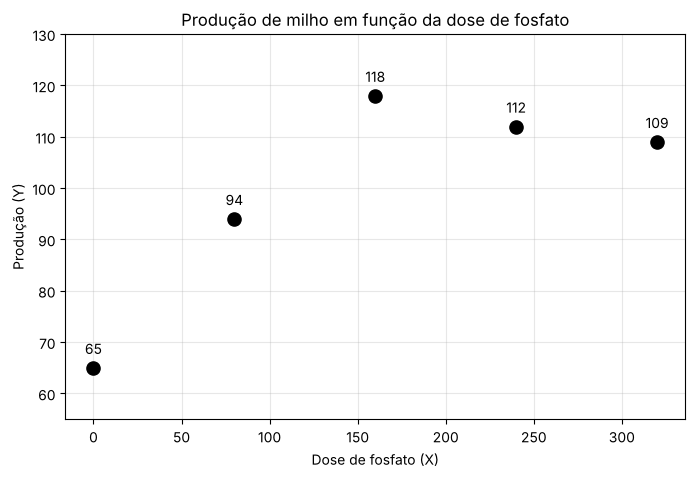

In [3]:
plt.scatter(X, Y, s=90, color="black", zorder=3)
for xi, yi in zip(X, Y):
    plt.annotate(f"{yi:.0f}", (xi, yi), textcoords="offset points", xytext=(0, 10), ha="center")
plt.title("Produção de milho em função da dose de fosfato")
plt.xlabel("Dose de fosfato (X)")
plt.ylabel("Produção (Y)")
plt.ylim(55, 130)
plt.show()

**O que o gráfico mostra:** os pontos formam um **"morro"** — sobem, chegam a um topo e descem um pouco.

Na agronomia isso tem nome: **lei dos rendimentos decrescentes**. No começo, cada dose extra de adubo ajuda muito. Depois, ajuda cada vez menos. Em excesso, pode até atrapalhar (toxicidade, desequilíbrio de nutrientes).

Os slides citam esse tipo de situação como aplicação clássica: **estudos de dose-resposta**.

## 3. Ferramentas de avaliação (funções auxiliares)

Antes de ajustar modelos, criamos duas "réguas" para medir a qualidade de qualquer modelo. Escrever isso uma vez só evita repetir código.

### R² — quanto o modelo explica

A ideia:

- **SQT (Soma dos Quadrados Total):** quanto Y varia em torno da própria média. É a "bagunça total" a ser explicada.
- **SQE (Soma dos Quadrados dos Erros):** quanto sobra de erro depois de usar o modelo.

$$R^2 = 1 - \frac{SQE}{SQT}$$

Se o modelo acerta tudo, SQE = 0 e R² = 1. Se o modelo não é melhor que "chutar a média", R² ≈ 0.

**Por que elevar ao quadrado?** Para que erros positivos e negativos não se cancelem, e para punir mais os erros grandes.

### AIC — qualidade com punição por complexidade

$$AIC = n \cdot \ln\left(\frac{SQE}{n}\right) + 2k$$

onde **k** é o número de parâmetros. Um modelo com mais parâmetros quase sempre erra menos, mas pode estar só "decorando" os dados. O termo **2k** é a multa por complexidade. **Quanto menor o AIC, melhor.**

> O slide de "Bondade de ajuste" cita exatamente essas duas medidas: R² e AIC.

In [4]:
def r2(y, y_prev):
    sqe = np.sum((y - y_prev) ** 2)          # erro que sobrou
    sqt = np.sum((y - y.mean()) ** 2)        # variação total
    return 1 - sqe / sqt

def aic(y, y_prev, k):
    sqe = np.sum((y - y_prev) ** 2)
    return len(y) * np.log(sqe / len(y)) + 2 * k

SQT = np.sum((Y - Y.mean()) ** 2)
print(f"Média de Y = {Y.mean():.2f}")
print(f"SQT (variação total a ser explicada) = {SQT:.2f}")

Média de Y = 99.60
SQT (variação total a ser explicada) = 1809.20


## 4. Modelo de referência — a reta (regressão linear)

**Por que ajustar uma reta se já sabemos que os dados são curvos?** Porque precisamos de uma **base de comparação**. Só vamos acreditar que o modelo não linear vale a pena se ele for claramente melhor que o modelo mais simples possível.

Modelo: **Y = β₀ + β₁·X**

- **β₀ (intercepto):** produção prevista sem fosfato (X = 0).
- **β₁ (inclinação):** quanto a produção muda a cada unidade de fosfato.

`np.polyfit(X, Y, 1)` encontra os valores de β que **minimizam a soma dos erros ao quadrado**. Esse é o método dos **Mínimos Quadrados Ordinários (MQO)**, o mesmo citado no slide da Unidade 1 ao comparar com a regressão bayesiana. O `1` indica grau 1 (reta).

In [5]:
coef_lin = np.polyfit(X, Y, 1)              # devolve [β1, β0]
Y_lin = np.polyval(coef_lin, X)             # valores previstos pela reta

print(f"Reta: Ŷ = {coef_lin[1]:.3f} + {coef_lin[0]:.4f}·X")
print(f"R²  = {r2(Y, Y_lin):.3f}")
print(f"AIC = {aic(Y, Y_lin, k=2):.2f}")

Reta: Ŷ = 78.400 + 0.1325·X
R²  = 0.621
AIC = 28.60


**Interpretação:** a reta explica só cerca de **62%** da variação. Ela erra justamente onde está a informação mais importante: não percebe que a produção **para de crescer e cai**. Se usássemos a reta, concluiríamos que "quanto mais fosfato, melhor", o que é **falso** para esses dados.

## 5. Modelo polinomial quadrático (parábola)
 *" Regressão polinomial"*: usado quando a relação **pode ser aproximada por um polinômio** e para **ajuste de curva** com uma única variável. É o nosso caso: uma variável (fosfato) e uma curva em forma de morro.

Modelo: **Y = β₀ + β₁·X + β₂·X²**

- O termo **X²** é o que permite a curva "dobrar".
- Se **β₂ for negativo**, a parábola tem a "boca para baixo" (∩), ou seja, tem um **ponto máximo**. É o que esperamos.

**Curiosidade importante:** esse modelo é uma curva em relação a X, mas é **linear nos parâmetros** (os β aparecem somados, sem estar dentro de exponenciais ou potências). Por isso dá para resolvê-lo com uma conta direta, sem método iterativo. Vamos fazer de dois jeitos para confirmar.

### 5a. Jeito rápido: `np.polyfit` com grau 2

In [6]:
coef_quad = np.polyfit(X, Y, 2)             # devolve [β2, β1, β0]
b2, b1, b0 = coef_quad
Y_quad = np.polyval(coef_quad, X)

print(f"Parábola: Ŷ = {b0:.3f} + {b1:.5f}·X + ({b2:.7f})·X²")
print(f"R²  = {r2(Y, Y_quad):.3f}")
print(f"AIC = {aic(Y, Y_quad, k=3):.2f}")

Parábola: Ŷ = 64.971 + 0.46821·X + (-0.0010491)·X²
R²  = 0.970
AIC = 17.94


### 5b. Jeito "na mão": as equações normais (para ver que não é mágica)

O MQO tem uma fórmula fechada em notação de matrizes:

$$\hat{\beta} = (X^T X)^{-1} X^T Y$$

Montamos a **matriz de planejamento** (chamada de `M` no código): cada linha é uma observação, e as colunas são **[1, X, X²]**. A coluna de 1s existe para gerar o intercepto β₀.

Não precisa decorar a fórmula. O objetivo aqui é só mostrar que o resultado do `polyfit` sai de uma conta que dá para conferir.

In [7]:
M = np.column_stack([np.ones(n), X, X**2])          # matriz [1, X, X²]
beta_mao = np.linalg.inv(M.T @ M) @ M.T @ Y         # (MᵀM)⁻¹ MᵀY

print("Matriz de planejamento M:\n", M)
print("\nβ calculados na mão :", np.round(beta_mao, 7))
print("β do polyfit        :", np.round([b0, b1, b2], 7))
print("São iguais?", np.allclose(beta_mao, [b0, b1, b2]))

Matriz de planejamento M:
 [[1.000e+00 0.000e+00 0.000e+00]
 [1.000e+00 8.000e+01 6.400e+03]
 [1.000e+00 1.600e+02 2.560e+04]
 [1.000e+00 2.400e+02 5.760e+04]
 [1.000e+00 3.200e+02 1.024e+05]]

β calculados na mão : [ 6.49714286e+01  4.68214300e-01 -1.04910000e-03]
β do polyfit        : [ 6.49714286e+01  4.68214300e-01 -1.04910000e-03]
São iguais? True


**Resultado:** **Ŷ ≈ 64,97 + 0,4682·X − 0,001049·X²**, com **R² ≈ 0,97**.

- β₂ é **negativo** → confirma o formato de morro (∩).
- O R² saltou de 0,62 (reta) para 0,97: a parábola explica **97%** da variação.

## 6. Os outros modelos dos slides — exponencial e potência

Para justificar a escolha, testamos também os outros dois tipos de modelo apresentados nos slides. Uma boa análise não escolhe o modelo "no achismo": ela mostra que as alternativas são piores.

Estes modelos **não** são lineares nos parâmetros, então precisam de **métodos iterativos** (slide *"2. Método de estimativa"*). O `curve_fit` do scipy usa o **Levenberg-Marquardt**, um dos métodos citados.

Métodos iterativos precisam de um **chute inicial** (`p0`). Um chute ruim pode fazer o algoritmo não convergir, por isso escolhemos valores razoáveis olhando os dados.

### 6a. Exponencial assintótico (modelo de Mitscherlich)

$$Y = A - B \cdot e^{-c \cdot X}$$

É a versão de "crescimento exponencial que se estabiliza", muito usada em adubação. **A** é o teto de produção. O problema: essa curva **sobe sempre e nunca desce**. Vamos ver o quanto isso custa.

### 6b. Potência

$$Y = a \cdot (X + 1)^b$$

O slide *"3. Regressão potência"* fala em fenômenos de lei de potência. Somamos 1 em X porque **0 elevado a qualquer potência dá 0**, o que obrigaria a curva a passar por produção zero sem adubo. Esta curva também é **monótona**: só sobe (ou só desce).

In [8]:
def mitscherlich(x, A, B, c):
    return A - B * np.exp(-c * x)

def potencia(x, a, b):
    return a * (x + 1) ** b

p_exp, _ = curve_fit(mitscherlich, X, Y, p0=[115, 50, 0.01], maxfev=20000)
p_pot, _ = curve_fit(potencia,     X, Y, p0=[60, 0.1],        maxfev=20000)

Y_exp = mitscherlich(X, *p_exp)
Y_pot = potencia(X, *p_pot)

print(f"Exponencial: Ŷ = {p_exp[0]:.2f} - {p_exp[1]:.2f}·e^(-{p_exp[2]:.5f}·X)")
print(f"  R² = {r2(Y, Y_exp):.3f} | AIC = {aic(Y, Y_exp, k=3):.2f}")
print(f"Potência:    Ŷ = {p_pot[0]:.2f}·(X+1)^{p_pot[1]:.4f}")
print(f"  R² = {r2(Y, Y_pot):.3f} | AIC = {aic(Y, Y_pot, k=2):.2f}")

Exponencial: Ŷ = 113.76 - 49.44·e^(-0.01490·X)
  R² = 0.934 | AIC = 21.86
Potência:    Ŷ = 64.98·(X+1)^0.0982
  R² = 0.896 | AIC = 22.13


## 7. Passo 3 dos slides — Comparar a bondade de ajuste

Juntamos tudo numa tabela e num gráfico. Lembre:

- **R²:** maior é melhor.
- **AIC:** menor é melhor (e já desconta a complexidade).

In [9]:
comparacao = pd.DataFrame({
    "Modelo": ["Linear (reta)", "Polinomial quadrático", "Exponencial (Mitscherlich)", "Potência"],
    "Nº parâmetros (k)": [2, 3, 3, 2],
    "R²": [r2(Y, Y_lin), r2(Y, Y_quad), r2(Y, Y_exp), r2(Y, Y_pot)],
    "AIC": [aic(Y, Y_lin, 2), aic(Y, Y_quad, 3), aic(Y, Y_exp, 3), aic(Y, Y_pot, 2)],
}).sort_values("AIC").reset_index(drop=True)
comparacao

,Modelo,Nº parâmetros (k),R²,AIC
0,Polinomial quadrático,3,0.9699,17.9399
1,Exponencial (Mitscherlich),3,0.9340,21.8648
2,Potência,2,0.8961,22.1339
3,Linear (reta),2,0.6210,28.6043


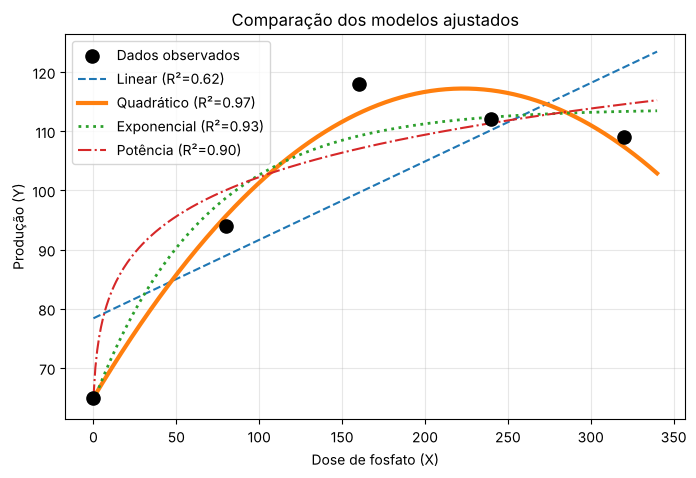

In [10]:
xs = np.linspace(0, 340, 300)                       # muitos pontos para desenhar curvas suaves
plt.scatter(X, Y, s=90, color="black", zorder=5, label="Dados observados")
plt.plot(xs, np.polyval(coef_lin, xs),  "--", label=f"Linear (R²={r2(Y, Y_lin):.2f})")
plt.plot(xs, np.polyval(coef_quad, xs), lw=3, label=f"Quadrático (R²={r2(Y, Y_quad):.2f})")
plt.plot(xs, mitscherlich(xs, *p_exp),  ":", lw=2, label=f"Exponencial (R²={r2(Y, Y_exp):.2f})")
plt.plot(xs, potencia(xs, *p_pot),      "-.", label=f"Potência (R²={r2(Y, Y_pot):.2f})")
plt.title("Comparação dos modelos ajustados")
plt.xlabel("Dose de fosfato (X)"); plt.ylabel("Produção (Y)")
plt.legend(); plt.show()

**Interpretação:**

- O **quadrático** tem o maior R² e o menor AIC. Visualmente, é o único que acompanha a **queda** depois de 160.
- O **exponencial** fica razoável, mas se estabiliza num teto e não consegue descer.
- A **potência** e a **reta** continuam subindo e erram bastante no final.

> **Cuidado:** com só 5 pontos, um modelo de 3 parâmetros tem pouquíssima "folga" (5 − 3 = 2 graus de liberdade). Os números de R² e AIC servem para **comparar** os modelos, mas não devem ser vistos como uma prova definitiva.

## 8. Passo 4 dos slides — Diagnóstico

O slide *"Pressupostos"* diz que os resíduos devem ter **distribuição normal** e **variância constante**. O slide *"Diagnóstico"* sugere duas ferramentas: **análise residual** e **distância de Cook**.

### 8a. Análise residual

Calculamos os resíduos (Y real − Y previsto) do modelo quadrático e os plotamos **contra os valores previstos**, exatamente como o slide recomenda.

**O que procurar no gráfico:**

- Pontos espalhados ao redor do zero, **sem formar desenho** → bom sinal.
- Um padrão (curva em U, funil abrindo) → o modelo está deixando escapar algo.

Fazemos o mesmo para a reta, para você ver como fica um resíduo "ruim".

In [11]:
res_quad = Y - Y_quad
res_lin  = Y - Y_lin

tabela_res = pd.DataFrame({
    "X": X, "Y real": Y,
    "Ŷ quadrático": Y_quad, "Resíduo quadrático": res_quad,
    "Ŷ linear": Y_lin,      "Resíduo linear": res_lin,
})
print(f"SQE quadrático = {np.sum(res_quad**2):.2f}   |   SQE linear = {np.sum(res_lin**2):.2f}")
tabela_res

SQE quadrático = 54.46   |   SQE linear = 685.60


,X,Y real,Ŷ quadrático,Resíduo quadrático,Ŷ linear,Resíduo linear
0,0.0000,65.0000,64.9714,0.0286,78.4000,-13.4000
1,80.0000,94.0000,95.7143,-1.7143,89.0000,5.0000
2,160.0000,118.0000,113.0286,4.9714,99.6000,18.4000
3,240.0000,112.0000,116.9143,-4.9143,110.2000,1.8000
4,320.0000,109.0000,107.3714,1.6286,120.8000,-11.8000


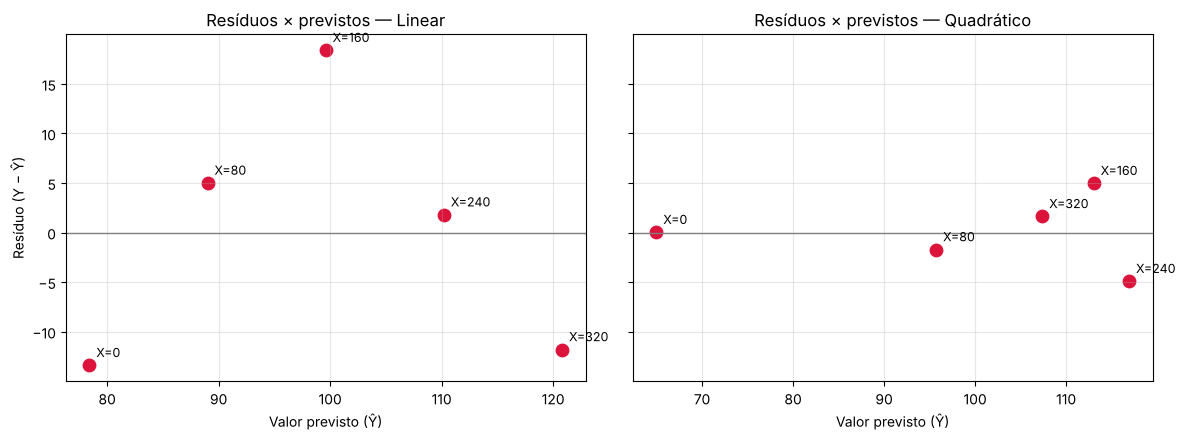

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, yp, res, nome in [(ax[0], Y_lin, res_lin, "Linear"), (ax[1], Y_quad, res_quad, "Quadrático")]:
    a.axhline(0, color="gray", lw=1)
    a.scatter(yp, res, s=80, color="crimson")
    for xi, xp, r in zip(X, yp, res):
        a.annotate(f"X={xi:.0f}", (xp, r), textcoords="offset points", xytext=(5, 6), fontsize=9)
    a.set_title(f"Resíduos × previstos — {nome}")
    a.set_xlabel("Valor previsto (Ŷ)")
ax[0].set_ylabel("Resíduo (Y − Ŷ)")
plt.tight_layout(); plt.show()

**Interpretação:**

- **Reta (esquerda):** os resíduos formam um **arco** (negativo, positivo, positivo, positivo, negativo). Esse desenho é a "impressão digital" de uma curvatura que a reta não captou.
- **Parábola (direita):** os resíduos são bem menores (no máximo ≈ ±5) e oscilam sem um padrão claro. É o comportamento esperado de um modelo adequado.

Com apenas 5 pontos, **testes formais de normalidade** (como Shapiro-Wilk) não têm poder estatístico suficiente para dizer nada confiável. Por isso ficamos com a inspeção visual.

### 8b. Distância de Cook — algum ponto está "mandando" no modelo?

O slide explica: a distância de Cook mede **quanto os parâmetros mudam quando retiramos uma observação**. Se tirar um ponto muda muito a curva, esse ponto é **influente**.

Para o cálculo, usamos a **alavancagem (h)** de cada ponto. Ela mede quão "afastado" o ponto está dos outros no eixo X. Pontos nas pontas (X = 0 e X = 320) costumam ter alavancagem alta.

$$D_i = \frac{e_i^2}{p \cdot s^2} \cdot \frac{h_i}{(1 - h_i)^2}$$

- **eᵢ:** resíduo do ponto i
- **p:** número de parâmetros (3)
- **s²:** variância estimada dos erros = SQE / (n − p)
- **hᵢ:** alavancagem, que vem da diagonal da "matriz chapéu" H = M (MᵀM)⁻¹ Mᵀ

**Regra prática:** D > 1 (ou, de forma mais rígida, D > 4/n) indica um ponto que merece atenção.

In [13]:
p = 3
H = M @ np.linalg.inv(M.T @ M) @ M.T         # matriz chapéu
h = np.diag(H)                               # alavancagem de cada ponto
s2 = np.sum(res_quad**2) / (n - p)           # variância dos erros
cook = (res_quad**2 / (p * s2)) * (h / (1 - h)**2)

tabela_cook = pd.DataFrame({"X": X, "Resíduo": res_quad, "Alavancagem (h)": h, "Distância de Cook": cook})
print(f"Limite rígido 4/n = {4/n:.2f}   |   Limite usual = 1.00")
tabela_cook

Limite rígido 4/n = 0.80   |   Limite usual = 1.00


,X,Resíduo,Alavancagem (h),Distância de Cook
0,0.0000,0.0286,0.8857,0.0007
1,80.0000,-1.7143,0.3714,0.0338
2,160.0000,4.9714,0.4857,0.5556
3,240.0000,-4.9143,0.3714,0.2779
4,320.0000,1.6286,0.8857,2.2018


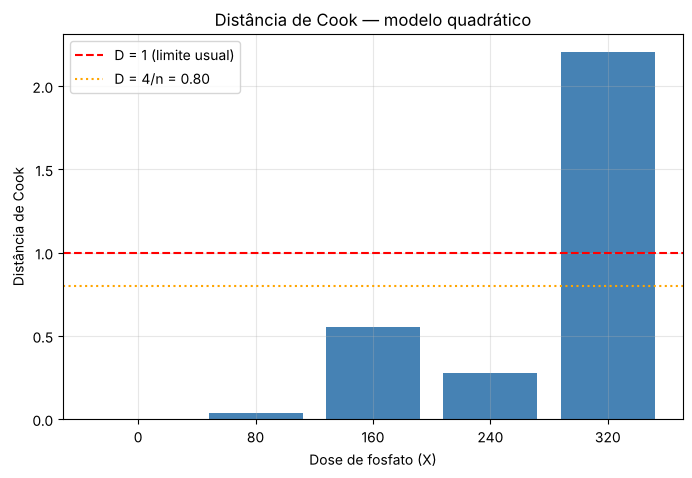

In [14]:
plt.bar(X.astype(int).astype(str), cook, color="steelblue")
plt.axhline(1, color="red", ls="--", label="D = 1 (limite usual)")
plt.axhline(4/n, color="orange", ls=":", label=f"D = 4/n = {4/n:.2f}")
plt.title("Distância de Cook — modelo quadrático")
plt.xlabel("Dose de fosfato (X)"); plt.ylabel("Distância de Cook")
plt.legend(); plt.show()

**Interpretação:**

- As pontas (X = 0 e X = 320) têm a maior alavancagem (≈ 0,89), porque são os pontos mais "afastados" no eixo X.
- **X = 0** tem Cook quase zero: a curva passa praticamente em cima dele.
- **X = 320 tem Cook ≈ 2,2, acima do limite de 1.** Ou seja, esse ponto **pesa muito** no formato da curva. Faz sentido: junto com X = 240, ele é a evidência de que a produção **cai** depois do pico. Sem ele, a parábola ficaria bem diferente e a dose ótima mudaria.

**O que fazer com isso?** Um ponto influente **não deve ser apagado** só por ser influente. Ele não parece erro de digitação (109 é coerente com 112 da dose anterior). A conclusão correta é: o resultado depende fortemente de poucas observações, e **o pesquisador deveria repetir o experimento nas doses altas** para confirmar a queda.

Com só 5 observações, tirar qualquer ponto deixa apenas 4 para estimar 3 parâmetros. Esse é mais um argumento para ler os resultados **com cautela**.

## 9. Interpretação prática — qual a dose ótima de fosfato?

Uma vantagem da parábola é que ela responde à pergunta que o pesquisador realmente quer saber: **até onde vale a pena adubar?**

O ponto mais alto de uma parábola (o **vértice**) fica onde a inclinação da curva é zero. Pela derivada:

$$\frac{dY}{dX} = \beta_1 + 2\beta_2 X = 0 \quad\Rightarrow\quad X^* = -\frac{\beta_1}{2\beta_2}$$

Depois, substituímos X* na fórmula para ver a produção máxima prevista.

Dose ótima estimada (X*) ≈ 223.1
Produção máxima prevista ≈ 117.2


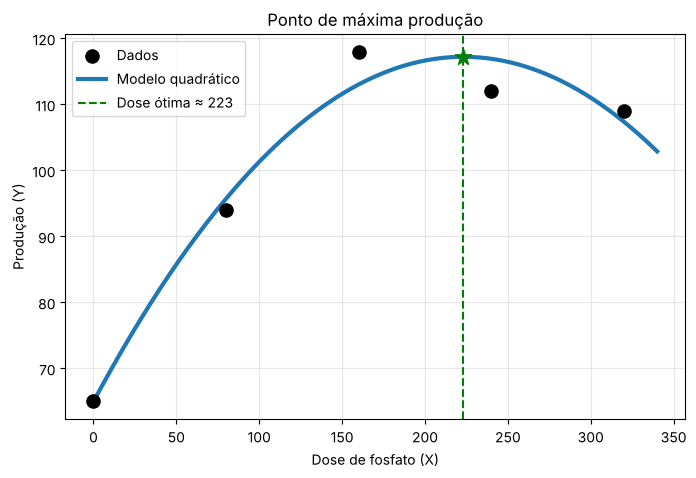

In [15]:
X_otimo = -b1 / (2 * b2)
Y_max = np.polyval(coef_quad, X_otimo)

print(f"Dose ótima estimada (X*) ≈ {X_otimo:.1f}")
print(f"Produção máxima prevista ≈ {Y_max:.1f}")

plt.scatter(X, Y, s=90, color="black", zorder=5, label="Dados")
plt.plot(xs, np.polyval(coef_quad, xs), lw=3, label="Modelo quadrático")
plt.axvline(X_otimo, color="green", ls="--", label=f"Dose ótima ≈ {X_otimo:.0f}")
plt.scatter([X_otimo], [Y_max], s=150, marker="*", color="green", zorder=6)
plt.title("Ponto de máxima produção")
plt.xlabel("Dose de fosfato (X)"); plt.ylabel("Produção (Y)")
plt.legend(); plt.show()

**Interpretação:** a produção máxima (≈ 117) ocorre com cerca de **223 unidades de fosfato**. Acima disso, gastar mais adubo **não aumenta** a produção e ainda pode reduzi-la.

O modelo exponencial nunca daria essa resposta, porque para ele "mais adubo nunca atrapalha".

## 10. Bônus (Unidade 1) — Quão confiáveis são esses números? Uma visão bayesiana

Até aqui, cada parâmetro foi **um único número** ("estimativa pontual"). A Unidade 1 mostra outra forma de pensar: tratar os parâmetros como **distribuições de probabilidade**.

O slide resume: *"se tivermos menos pontos de dados, a distribuição posterior será mais dispersa"*. Com só 5 pontos, esperamos uma incerteza **grande**. Vamos medir isso.

### Como funciona (sem jargão)

1. **Priori (anterior):** o que acreditamos antes de ver os dados. Usamos uma priori **não informativa** ("não sei nada"), como os slides sugerem quando não há conhecimento prévio.
2. **Verossimilhança:** o quanto cada combinação de parâmetros explica bem os dados.
3. **Posteriori:** combinação das duas pelo Teorema de Bayes. É a distribuição de valores plausíveis para os parâmetros **depois** de ver os dados.

### Como sorteamos da posteriori

Os slides usam **MCMC** (com bibliotecas como PyMC), que serve para qualquer modelo. Para este caso específico (modelo linear nos parâmetros + priori não informativa), a matemática já conhece a forma exata da posteriori. Então podemos **sortear direto dela**, que dá o mesmo resultado que o MCMC chegaria, sem precisar instalar nada extra:

1. Sorteamos a variância do erro **σ²** (ela segue uma distribuição qui-quadrado invertida com n − p graus de liberdade).
2. Dado esse σ², sorteamos os **β** de uma distribuição Normal centrada nas estimativas do MQO.
3. Repetimos isso **20.000 vezes**. Cada repetição é uma curva plausível.

Para cada sorteio, calculamos também a **dose ótima**. Assim, vemos quão incerta ela é.

In [16]:
N_SORTEIOS = 20_000
gl = n - p                                          # graus de liberdade = 2
XtX_inv = np.linalg.inv(M.T @ M)
beta_hat = beta_mao
s2_hat = np.sum(res_quad**2) / gl

# passo 1: sortear σ²
sigma2 = gl * s2_hat / np.random.chisquare(gl, size=N_SORTEIOS)

# passo 2: sortear β dado σ²
L = np.linalg.cholesky(XtX_inv)
z = np.random.standard_normal((N_SORTEIOS, 3))
betas = beta_hat + np.sqrt(sigma2)[:, None] * (z @ L.T)

# dose ótima de cada curva sorteada (só faz sentido quando β2 < 0, ou seja, curva com máximo)
tem_maximo = betas[:, 2] < 0
dose_otima = -betas[tem_maximo, 1] / (2 * betas[tem_maximo, 2])

print(f"Curvas com formato de morro (β2 < 0): {tem_maximo.mean():.1%} dos sorteios")
resumo = pd.DataFrame({
    "Parâmetro": ["β0 (intercepto)", "β1 (X)", "β2 (X²)", "Dose ótima"],
    "Mediana":   [np.median(betas[:, 0]), np.median(betas[:, 1]), np.median(betas[:, 2]), np.median(dose_otima)],
    "Limite inferior (95%)": [np.percentile(betas[:, 0], 2.5), np.percentile(betas[:, 1], 2.5),
                              np.percentile(betas[:, 2], 2.5), np.percentile(dose_otima, 2.5)],
    "Limite superior (95%)": [np.percentile(betas[:, 0], 97.5), np.percentile(betas[:, 1], 97.5),
                              np.percentile(betas[:, 2], 97.5), np.percentile(dose_otima, 97.5)],
})
resumo

Curvas com formato de morro (β2 < 0): 98.1% dos sorteios


,Parâmetro,Mediana,Limite inferior (95%),Limite superior (95%)
0,β0 (intercepto),64.9868,43.6867,86.2162
1,β1 (X),0.4681,0.1551,0.7938
2,β2 (X²),-0.0010,-0.0020,-0.0001
3,Dose ótima,222.4973,178.7859,356.0528


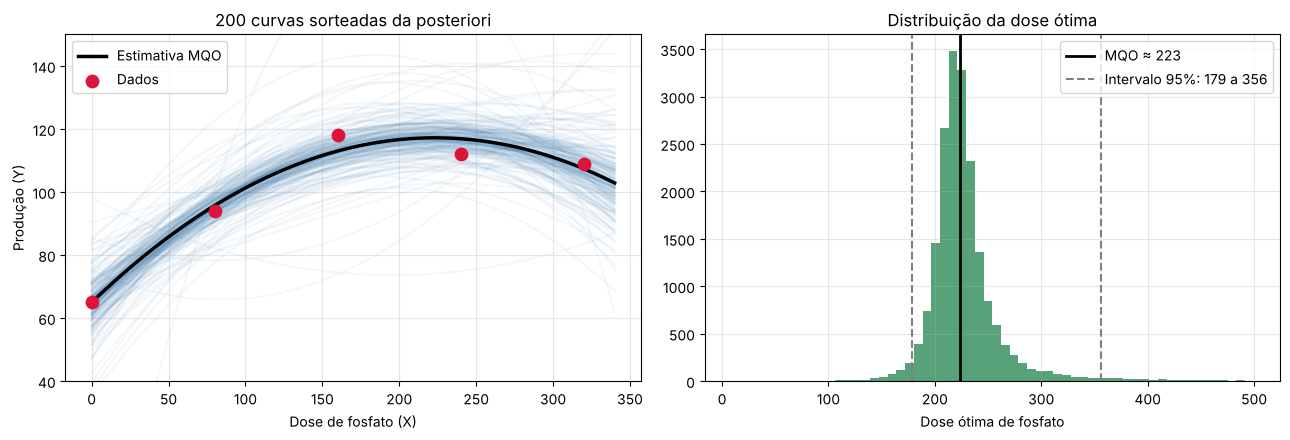

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# esquerda: 200 curvas plausíveis
for b in betas[np.random.choice(N_SORTEIOS, 200, replace=False)]:
    ax[0].plot(xs, b[0] + b[1]*xs + b[2]*xs**2, color="steelblue", alpha=0.06)
ax[0].plot(xs, np.polyval(coef_quad, xs), color="black", lw=2.5, label="Estimativa MQO")
ax[0].scatter(X, Y, s=80, color="crimson", zorder=5, label="Dados")
ax[0].set_ylim(40, 150)
ax[0].set_title("200 curvas sorteadas da posteriori")
ax[0].set_xlabel("Dose de fosfato (X)"); ax[0].set_ylabel("Produção (Y)"); ax[0].legend()

# direita: distribuição da dose ótima
lo, hi = np.percentile(dose_otima, [2.5, 97.5])
ax[1].hist(dose_otima[(dose_otima > 0) & (dose_otima < 500)], bins=60, color="seagreen", alpha=0.8)
ax[1].axvline(X_otimo, color="black", lw=2, label=f"MQO ≈ {X_otimo:.0f}")
ax[1].axvline(lo, color="gray", ls="--", label=f"Intervalo 95%: {lo:.0f} a {hi:.0f}")
ax[1].axvline(hi, color="gray", ls="--")
ax[1].set_title("Distribuição da dose ótima")
ax[1].set_xlabel("Dose ótima de fosfato"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretação:**

- **Gráfico da esquerda:** cada linha azul clara é uma curva compatível com os dados. Perto dos pontos observados elas se juntam, e entre ou além deles se espalham. É o "intervalo de linhas" que o slide da Unidade 1 descreve.
- **Gráfico da direita:** a dose ótima **não é exatamente 223**. É uma faixa de valores plausíveis, e essa faixa é **larga**, porque temos apenas 5 observações.

Isso confirma, com números, o alerta dos slides: modelos não lineares **exigem mais dados**. A forma da curva (morro) é bem sustentada, mas o valor exato da dose ótima ainda é incerto. Mais doses testadas, ou repetições de cada dose, estreitariam essa faixa.

## 11. Conclusão 

| Pergunta | Resposta | Evidência no notebook |
|---|---|---|
| Regressão não linear vale para **qualquer** cenário? | **Não.** Depende da forma dos dados e da pergunta de pesquisa, e exige dados suficientes. | Seções 2, 8b e 10 |
| Qual modelo é mais adequado? | **Polinomial quadrático**, Ŷ ≈ 64,97 + 0,468X − 0,00105X² | Seções 5 e 7 (maior R², menor AIC) |
| Como fazer a análise? | Gráfico → ajuste de candidatos → R²/AIC → resíduos e Cook → interpretação | Seções 2 a 9 |
| Resultado prático | Dose ótima ≈ 223, produção máxima ≈ 117 | Seção 9 |
| Limitação | Só 5 pontos; o ponto X = 320 é muito influente (Cook ≈ 2,2); a dose ótima pode estar entre ≈ 179 e ≈ 356 | Seções 8b e 10 |